# 1. Bayesian MMM on simulated data with a known ROI

The point of simulating is that the true return on each channel is known, so I can check
what a standard marketing mix model gets right and what it gets wrong.

The simulated business spends on three channels (TV, search, social) for three years of
weekly data. Sales depend on a trend, seasonality, promotions, the media effects, and an
**unobserved demand shock**. Search budgets track query volume, and TV flights get bigger
budgets when demand is expected to be high, so both channels' spend moves with the shock.
Social spend is planned independently of demand. The MMM sees spend, promotions, trend and
seasonality, but not the shock.

Data-generating process (same functional form as PyMC-Marketing):

$$\text{sales}_t = \text{base}_t + \text{shock}_t + \sum_c \beta_c \,\text{logistic}\!\left(\text{adstock}(x_{c,t};\alpha_c);\lambda_c\right) + \varepsilon_t$$

In [1]:
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pymc_extras.prior import Prior
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

from simulate import CHANNELS, default_holdout, simulate_world

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SAMPLER = dict(nuts_sampler="numpyro", chains=4, draws=1000, tune=1000, target_accept=0.95, progressbar=False)

## The simulated data

The world includes the geo holdout used in notebook 2 (search turned off in 10 of 40 geos
for 7 weeks), so the national series here is the same one the business would actually observe.

In [2]:
world = simulate_world(holdout=default_holdout())
nat, truth = world["national"], world["truth"]
truth[["channel", "spend", "contribution", "roi", "alpha", "lam"]].round(2)

,channel,spend,contribution,roi,alpha,lam
0,tv,4107.59,10994.01,2.68,0.6,2.0
1,search,3534.43,10518.37,2.98,0.1,3.0
2,social,4720.88,5664.11,1.20,0.3,1.5


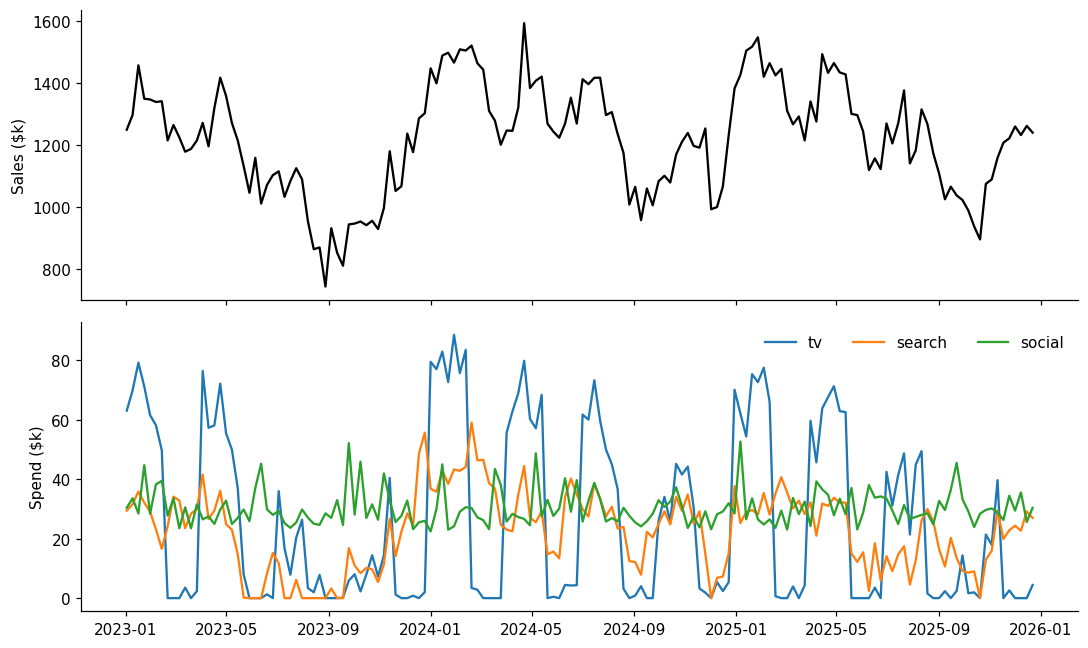

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(nat["date"], nat["sales"], color="black")
axes[0].set_ylabel("Sales ($k)")
for c in CHANNELS:
    axes[1].plot(nat["date"], nat[c], label=c)
axes[1].set_ylabel("Spend ($k)")
axes[1].legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig("../figures/data.png", bbox_inches="tight")

In [4]:
pd.Series({c: np.corrcoef(nat[c], world["shock"])[0, 1] for c in CHANNELS}, name="corr(spend, demand shock)").round(2)

tv        0.34
search    0.85
social    0.00
Name: corr(spend, demand shock), dtype: float64

## Fit the MMM with default priors

Geometric adstock (up to 8 weeks), logistic saturation, two yearly Fourier terms, and
promotions and a linear trend as controls. The default priors are Beta(1, 3) for carryover,
Gamma(3, 1) for the saturation curvature and HalfNormal(2) for channel coefficients.

In [5]:
X = nat[["date", *CHANNELS, "promo", "trend"]]
y = nat["sales"]


def make_mmm(model_config=None):
    return MMM(
        date_column="date",
        channel_columns=CHANNELS,
        control_columns=["promo", "trend"],
        adstock=GeometricAdstock(l_max=8),
        saturation=LogisticSaturation(),
        yearly_seasonality=2,
        model_config=model_config,
    )


def posterior_roi(mmm):
    contrib = mmm.compute_channel_contribution_original_scale().sum("date")
    roi = contrib / xr_spend
    return roi.stack(sample=("chain", "draw")).transpose("sample", "channel").to_pandas()


xr_spend = xr.DataArray(nat[CHANNELS].sum().to_numpy(), dims="channel", coords={"channel": CHANNELS})

mmm = make_mmm()
mmm.fit(X, y, random_seed=1, **SAMPLER)
az.summary(mmm.fit_result, var_names=["adstock_alpha", "saturation_lam", "saturation_beta"])[
    ["mean", "hdi_3%", "hdi_97%", "r_hat", "ess_bulk"]
].round(3)

There were 36 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,hdi_3%,hdi_97%,r_hat,ess_bulk
adstock_alpha[tv],0.619,0.564,0.674,1.00,2350.0
adstock_alpha[search],0.107,0.018,0.193,1.00,2172.0
adstock_alpha[social],0.235,0.000,0.551,1.00,1882.0
saturation_lam[tv],2.341,0.872,3.694,1.00,1147.0
saturation_lam[search],1.614,0.745,2.468,1.00,1497.0
saturation_lam[social],3.312,0.119,7.445,1.01,917.0
saturation_beta[tv],0.180,0.108,0.281,1.00,1091.0
saturation_beta[search],0.392,0.230,0.619,1.00,1512.0
saturation_beta[social],0.111,0.002,0.273,1.00,1514.0


In [6]:
print("divergences:", int(mmm.idata.sample_stats["diverging"].sum()))

divergences: 36


## Does the model recover the true ROI?

In [7]:
roi_default = posterior_roi(mmm)


def roi_table(samples, label):
    q = samples.quantile([0.05, 0.5, 0.95]).T
    q.columns = ["p05", "median", "p95"]
    q["true_roi"] = truth.set_index("channel")["roi"]
    q["covers_truth"] = (q["p05"] <= q["true_roi"]) & (q["true_roi"] <= q["p95"])
    q.insert(0, "model", label)
    return q.round(2)


roi_table(roi_default, "default priors")

,model,p05,median,p95,true_roi,covers_truth
channel,,,,,,
tv,default priors,2.54,2.91,3.31,2.68,True
search,default priors,6.67,7.26,7.88,2.98,False
social,default priors,0.66,2.22,11.63,1.20,True


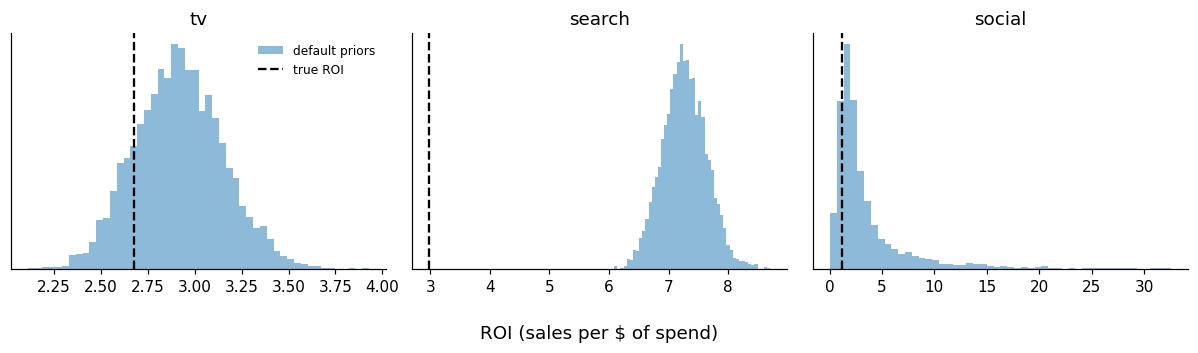

In [8]:
def plot_roi(samples_by_label, fname=None):
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(11, 3.2))
    for ax, c in zip(axes, CHANNELS):
        for label, s in samples_by_label.items():
            ax.hist(s[c], bins=50, alpha=0.5, density=True, label=label)
        ax.axvline(truth.set_index("channel").at[c, "roi"], color="black", ls="--", label="true ROI")
        ax.set_title(c)
        ax.set_yticks([])
    axes[0].legend(frameon=False, fontsize=8)
    fig.supxlabel("ROI (sales per $ of spend)")
    fig.tight_layout()
    if fname:
        fig.savefig(fname, bbox_inches="tight")


plot_roi({"default priors": roi_default}, "../figures/roi_default.png")

**Reading the result.** TV is recovered well (median 2.91 against a true 2.68): its spend
is only partly driven by the shock, and the flighting creates on/off variation the model can
use. Search is overstated by a factor of about 2.4 (7.26 against 2.98), and the 90% interval
is far from the truth. Its spend has a 0.85 correlation with the demand shock, so the model
credits search with sales that demand would have produced anyway. Social is uncorrelated with
the shock but its spend barely varies, so the interval runs from 0.7 to 11.6. A longer sample
or a better sampler would not fix search; the information needed to separate it from demand
is not in this time series.

The sampler reports some divergent transitions (36 of 4,000 draws). R-hat is 1.00–1.01 and
effective sample sizes are above 900 for every media parameter, so I keep the fit, but in a
real engagement I would reparameterize before reporting numbers.

## Prior sensitivity

With 156 observations and three channels, carryover and saturation are only weakly
identified, so priors matter. I refit with a prior that expects long carryover,
Beta(3, 1) instead of Beta(1, 3), and a tighter prior on the channel coefficients.

In [9]:
alt_config = make_mmm().default_model_config
alt_config["adstock_alpha"] = Prior("Beta", alpha=3, beta=1, dims="channel")
alt_config["saturation_beta"] = Prior("HalfNormal", sigma=0.5, dims="channel")

mmm_alt = make_mmm(model_config=alt_config)
mmm_alt.fit(X, y, random_seed=2, **SAMPLER)
print("divergences:", int(mmm_alt.idata.sample_stats["diverging"].sum()))
roi_alt = posterior_roi(mmm_alt)

pd.concat([roi_table(roi_default, "default priors"), roi_table(roi_alt, "long-carryover prior")])

There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


divergences: 7


,model,p05,median,p95,true_roi,covers_truth
channel,,,,,,
tv,default priors,2.54,2.91,3.31,2.68,True
search,default priors,6.67,7.26,7.88,2.98,False
social,default priors,0.66,2.22,11.63,1.20,True
tv,long-carryover prior,2.52,2.87,3.27,2.68,True
search,long-carryover prior,6.79,7.39,8.02,2.98,False
social,long-carryover prior,0.45,1.79,3.97,1.20,True


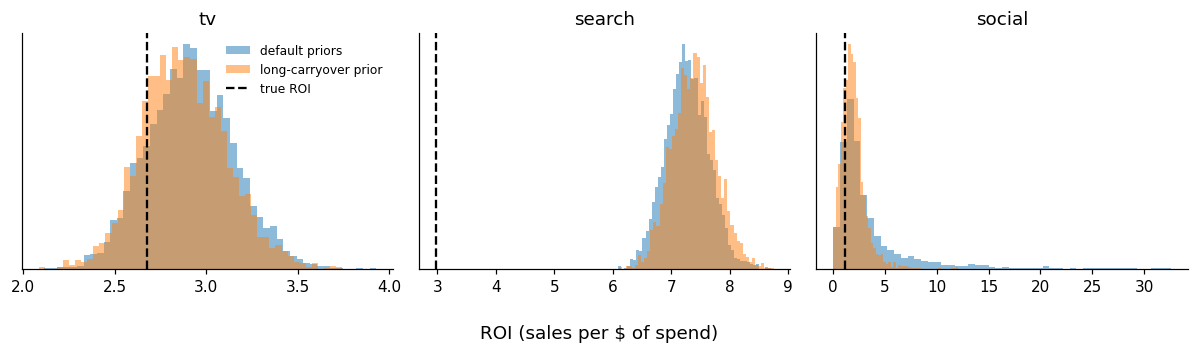

In [10]:
plot_roi({"default priors": roi_default, "long-carryover prior": roi_alt}, "../figures/roi_prior_sensitivity.png")

In [11]:
az.summary(mmm_alt.fit_result, var_names=["adstock_alpha"])[["mean", "hdi_3%", "hdi_97%"]].round(2)

,mean,hdi_3%,hdi_97%
adstock_alpha[tv],0.62,0.56,0.67
adstock_alpha[search],0.14,0.06,0.22
adstock_alpha[social],0.62,0.28,1.00


Under the long-carryover prior, TV and search barely move: the data pin down their
carryover. Social's carryover jumps from 0.24 to 0.62, close to the prior mean, and its ROI
interval narrows from 0.7–11.6 to 0.5–4.0. That narrowing comes from the prior, not from the
data. Neither prior fixes search, since the problem there is confounding rather than the shape
of the response curve.

## Save for notebook 2

In [12]:
roi_default.to_csv("../results/roi_uncalibrated_draws.csv", index=False)
roi_table(roi_default, "default priors").to_csv("../results/roi_uncalibrated_summary.csv")